<a href="https://colab.research.google.com/github/fataei/Deep-Learning-Projects/blob/main/vgg16.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import os
import nibabel as nib
import glob
import numpy as np
import torch
import torchvision
import torch.nn as nn
import torchvision.transforms as TF
from torch.utils.data import Dataset
from torchvision import transforms
import pandas as pd
#dir(models)


In [ ]:
#mount google drive for loading the dataset
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
import zipfile
import os

def extract_folder(zip_file_path, folder_name, destination_folder):
    try:
        with zipfile.ZipFile(zip_file_path, 'r') as zip_ref:
            # Get a list of all files and folders in the ZIP archive
            all_files = zip_ref.namelist()

            # Filter files and folders to include only those in the specified folder
            folder_files = [file for file in all_files if file.startswith(folder_name)]

            # Extract files and folders to the destination folder
            for file in folder_files:
                zip_ref.extract(file, destination_folder)

        print(f"Successfully extracted the '{folder_name}' folder.")
    except zipfile.BadZipFile:
        print("Error: The file is not a valid ZIP archive.")
    except FileNotFoundError:
        print("Error: File not found.")
    except Exception as e:
        print(f"An error occurred: {e}")

In [ ]:
extract_folder("/content/drive/MyDrive/Copy of computed_tomography_images_for_intracranial_hemorrhage_detection.zip","computed-tomography-images-for-intracranial-hemorrhage-detection-and-segmentation-1.3.1", ".")


Successfully extracted the 'computed-tomography-images-for-intracranial-hemorrhage-detection-and-segmentation-1.3.1' folder.


In [ ]:
import os
import shutil

def move_files(source_folder, destination_folder):
    try:
        # Get a list of all files in the source folder
        files = os.listdir(source_folder)

        # Move each file from the source folder to the destination folder
        for file in files:
            source_path = os.path.join(source_folder, file)
            destination_path = os.path.join(destination_folder, file)
            shutil.move(source_path, destination_path)

        print("All files moved successfully.")
    except FileNotFoundError:
        print("Error: Source or destination folder not found.")
    except Exception as e:
        print(f"An error occurred: {e}")

move_files("computed-tomography-images-for-intracranial-hemorrhage-detection-and-segmentation-1.3.1", ".")

All files moved successfully.


In [ ]:
drive.flush_and_unmount()

In [ ]:
#adopt the model with the dataset
model=torchvision.models.vgg16(pretrained=True)
model.features[0] = nn.Conv2d(1, 64, 3, 1, 1)
weight = model.features[0].weight.clone()
model.classifier[6] = torch.nn.Linear(4096,2)

#freeze the first 23 layers
for idx, param in enumerate(model.parameters()):
    param.requires_grad = False
    if idx == 23:
        break
print(model)

/usr/local/lib/python3.10/dist-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/usr/local/lib/python3.10/dist-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=VGG16_Weights.IMAGENET1K_V1`. You can also use `weights=VGG16_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)
Downloading: "https://download.pytorch.org/models/vgg16-397923af.pth" to /root/.cache/torch/hub/checkpoints/vgg16-397923af.pth
100%|██████████| 528M/528M [00:02<00:00, 207MB/s]


VGG(
  (features): Sequential(
    (0): Conv2d(1, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU(inplace=True)
    (2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (3): ReLU(inplace=True)
    (4): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (5): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (6): ReLU(inplace=True)
    (7): Conv2d(128, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (8): ReLU(inplace=True)
    (9): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (10): Conv2d(128, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (11): ReLU(inplace=True)
    (12): Conv2d(256, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (13): ReLU(inplace=True)
    (14): Conv2d(256, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (15): ReLU(inplace=True)
    (16): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1

In [ ]:
# model=torchvision.models.vgg19(pretrained=True)
# print(model)

In [ ]:
# param_ct=0
# arr=[]
# for child in model.children():
#   param_ct=0
#   for param in child.parameters():
#     param_ct += 1
#   arr.append(param_ct)
# print(arr)
# print(len(arr))
# print(sum(arr))

In [ ]:
# ct = 0
# for child in model.children():
#   ct += 1
#   if ct < 8:
#       for param in child.parameters():
#           param.requires_grad = False

In [ ]:
"""a program to convert a nifti file to a numpy form

Atributes:
------------
    path: str
        the directory where the nifti files are located
    images_path: list of str
        the path of nii images as a list

Methods:
------------
    convert(w_level=40, w_width=120, save_to="..\converted dataset"):
        convert and save nifti files to a numpy file
"""

import os
import nibabel as nib
import glob
import numpy as np


class nii2npy:
    def __init__(self, path):
        """get the path of the nifti file
        Args:
            path (str): the directory of the nifti file
        """
        self.dirPath = os.path.dirname(os.path.abspath('__file__'))
        self.path = os.path.join(self.dirPath, path)  # obtain folder directory
        self.images_path = glob.glob(os.path.join(self.path, "*.nii"))

    def _window(self, ct_scan, w_level, w_width):
        """extract bone information or subdural information
        Args:
            ct_scan (npy): 3-D array of CT-scan image
            w_level (int, optional): find it in dataset instruction.
            w_width (int, optional): find it in dataset instruction.

        Returns:
            numpy array: extracted information from original CT-scan image
        """
        w_min = w_level - w_width / 2
        w_max = w_level + w_width / 2
        num_slices = ct_scan.shape[2]
        for s in range(num_slices):
            slice_s = ct_scan[:, :, s]
            slice_s = (slice_s - w_min) * (255 / (w_max - w_min))
            slice_s[slice_s < 0] = 0
            slice_s[slice_s > 255] = 255
            ct_scan[:, :, s] = slice_s
        return ct_scan

    def _get_name(self, path: str, extentinon: str = ".nii") -> str:
        """Returns a name to save numpy array"""
        splited_path = path.split("/")
        return splited_path[-1].replace(extentinon, "")

    def convert(
        self,
        w_level=40,
        w_width=120,
        dir_name="converted_dataset",
        isMask=False,
        extend=False,
        crop = False,
        crop_size = 128
    ):
        """convert and save nifti as numpy array

        Args:
            w_level (int, optional): check dataset instruction.
            Defaults to 40.
            w_width (int, optional):check dataset instruction.
            Defaults to 120.
            save_to (str, optional):path to save your files.
            Defaults to "..\converted dataset".
            extend (bool, optional): whether to save slices individually or not
        """
        save_to = self.dirPath
        while os.listdir(save_to).count("__init__.py"):
            save_to, _ = os.path.split(save_to)
        paths = dir_name.split("/")
        for path in paths:
            if not os.path.exists(os.path.join(save_to, path)):
                save_to = os.path.join(save_to, path)
                os.mkdir(save_to)
            else:
                save_to = os.path.join(save_to, path)
        for path in self.images_path:
            ct = nib.load(path)
            ct = ct.get_fdata()
            if not isMask:
                ct = self._window(ct, w_level, w_width)

            ct = ct.astype(np.uint8)

            name = self._get_name(path)
            if extend:
                for i in range(ct.shape[-1]):
                    np.save(os.path.join(save_to, name + "_" + str(i)), ct[:, :, i])
            elif crop:
                for i in range(math.ceil(ct.shape.max()/crop_size)):
                    for j in range(math.ceil(ct.shape.max()/crop_size)):
                        np.save(os.path.join(
                            save_to, name + "_" + str(i)+"_"+str(j)), ct[:, :, :])
            else:
                np.save(os.path.join(save_to, name), ct)
                print(str(name) + "   " + str(ct.max()) + "   " + str(ct.min()))


if __name__ == "__main__":
    # farayand path
    # mask_paths = ["..\\dataSet\\train_masks", "..\\dataSet\\val_masks"]
    # image_paths = ["..\\dataSet\\train_cts", "..\\dataSet\\val_cts"]

    # mohammad path
    # paths = ["..\dataSet\ct_scans", "..\dataSet\masks"]

    #mehdi path:
    image_paths=["ct_scans"]
    mask_paths=["masks"]

    # test path
    # paths = ["..\\dataSet\\masks"]

    for path in image_paths:
        print("path to convert is: " + path)
        data = nii2npy(path)
        save_path = os.path.join("converted_dataset", path.split("/")[-1])
        data.convert(dir_name=save_path, isMask=False, extend = True)

    for path in mask_paths:
        print("path to convert is: " + path)
        data = nii2npy(path)
        save_path = os.path.join("converted_dataset", path.split("/")[-1])
        data.convert(dir_name=save_path, isMask=True, extend = True)


path to convert is: ct_scans
path to convert is: masks


In [ ]:
import sys
from pathlib import Path
try:
  os.mkdir("./converted_dataset/label")
except:
  pass
# Reading labels
hemorrhage_diagnosis_df = pd.read_csv("./hemorrhage_diagnosis_raw_ct.csv")
hemorrhage_diagnosis_array = hemorrhage_diagnosis_df.to_numpy()


hemorage_slices=[]
nohemorage_slices=[]

for sNo in range(49, 131):
    if sNo>58 and sNo<66: #no raw data were available for these subjects
        next
    else:
        idx = hemorrhage_diagnosis_array[:, 0] == sNo
        sliceNos = hemorrhage_diagnosis_array[idx, 1]
        NoHemorrhage = hemorrhage_diagnosis_array[idx, 7]

        for i in range(len(sliceNos)) :
            if NoHemorrhage[i] == 0:
                hemorage_slices.append("{0:0=3d}".format(sNo)+"_"+str(i))
            else :
                nohemorage_slices.append("{0:0=3d}".format(sNo)+"_"+str(i))

            np.save(os.path.join(
                            "./converted_dataset/label", "{0:0=3d}".format(sNo)+"_"+str(i)), NoHemorrhage[i].astype(np.uint8))

np.save("./converted_dataset/hemorage_slices",hemorage_slices)
np.save("./converted_dataset/nohemorage_slices",nohemorage_slices)

# NoHemorrhage = hemorrhage_diagnosis_array[:, 7]
# np.set_printoptions(threshold=sys.maxsize)
# np.save(os.path("./converted_dataset/label"),NoHemorrhage)




In [ ]:
# slices with hemmorage
print(len(np.load("./converted_dataset/hemorage_slices.npy")))
print(len(np.load("./converted_dataset/nohemorage_slices.npy")))

318
2496


In [ ]:
path1 = "./converted_dataset/train_img/"
path2 = "./converted_dataset/train_label/"
path3 = "./converted_dataset/val_label/"
path4 = "./converted_dataset/val_img/"
try:
  os.mkdir(path1[:-1])
  os.mkdir(path2[:-1])
  os.mkdir(path3[:-1])
  os.mkdir(path4[:-1])
except:
  pass
for i in os.listdir(path1):
    os.remove(path1+i)
for i in os.listdir(path2):
    os.remove(path2+i)
for i in os.listdir(path3):
    os.remove(path3+i)
for i in os.listdir(path4):
    os.remove(path4+i)


In [ ]:
import random
import albumentations as albu


arr=[]
val_h=[]
while  len(arr)<64:
      a=random.randint(0,317)
      if a not in arr:
          val_h.append(hemorage_slices[a])
          arr.append(a)
          ct_name=np.load("./converted_dataset/ct_scans/"+str(hemorage_slices[a])+".npy")
          label_name=np.load("./converted_dataset/label/"+str(hemorage_slices[a])+".npy")
          np.save("./converted_dataset/val_label/"+str(hemorage_slices[a]),label_name.astype(np.uint8))
          np.save("./converted_dataset/val_img/" + str(hemorage_slices[a]),ct_name.astype(np.uint8))

val_nh=[]
arr2=[]
while  len(arr2)<499:
    a=random.randint(0,2495)
    if a not in arr2:
        val_nh.append(nohemorage_slices[a])
        arr2.append(a)
        ct_name=np.load("./converted_dataset/ct_scans/"+str(nohemorage_slices[a])+".npy")
        label_name=np.load("./converted_dataset/label/"+str(nohemorage_slices[a])+".npy")
        np.save("./converted_dataset/val_label/"+str(nohemorage_slices[a]),label_name.astype(np.uint8))
        np.save("./converted_dataset/val_img/" + str(nohemorage_slices[a]),ct_name.astype(np.uint8))

for x in hemorage_slices+nohemorage_slices:
    if x not in val_h+val_nh:
        ct_name=np.load("./converted_dataset/ct_scans/"+str(x)+".npy")
        label_name=np.load("./converted_dataset/label/"+str(x)+".npy")
        np.save("./converted_dataset/train_label/"+str(x),label_name.astype(np.uint8))
        np.save("./converted_dataset/train_img/" + str(x),ct_name.astype(np.uint8))



In [ ]:
class CTDataset(Dataset):
    """a class to import CT scans into the framework"""

    def __init__(
        self,
        image_dir: str,
        label_dir: str,
        augment=False,
#         resize=False,
#         resize_size: tuple[int, int] = (128, 128),
    ) -> None:
        """_summary_

        Args:
            image_dir (str): pass image directory.
            mask_dir (str): pass mask directory.
            resize (bool, optional): if you need resize switch this
            to True. Defaults to True.
            resize_size (tuple[int, int], optional): if resize is Ture
            pass output dimensions. Defaults to (128, 128).
        """
        self.image_dir = image_dir
        self.label_dir = label_dir
        self.images = os.listdir(image_dir)
        self.labels = os.listdir(label_dir)
        # self.augment = augment
        # self.preprocess = albu.Compose([albu.HorizontalFlip(p=0.5),
        #                                 albu.VerticalFlip(p=0.5),
        #                                 albu.Rotate(p=0.5)
        #                                 ])
#         self.resize = resize
#         self.resize_size = resize_size

#         if resize:
#             self.resize_func = TF.Resize(size=resize_size)

    def __len__(self) -> int:
        return len(self.images)

    def __getitem__(self, index: int) -> torch.Tensor:
        img_path = os.path.join(self.image_dir, self.images[index])
        label_path = os.path.join(self.label_dir, self.labels[index])

        image = np.load(img_path)
        label = np.load(label_path)

        # if self.augment:
        #     augmented  = self.preprocess(image=image)
        #     image = augmented['image']
        image = transforms.Compose([
            transforms.ToTensor(),
            transforms.Normalize(np.mean([0.485, 0.456, 0.406]), np.mean([0.229, 0.224, 0.225]))
        ])(image)
        """convert images from numpy to tensor"""
        # image = transforms.Compose([transforms.ToTensor()])(image)
        label = torch.from_numpy(label)

        """because of 3D structure in pytorch we should make sure that
        input dimensions are equal to 5"""
#         image = torch.unsqueeze(image, dim=1).float()
#         label = torch.unsqueeze(label, dim=1).float()

#         if self.resize:
#             image = (
#                 self.resize_func(image) / 255.0
#             )  # normalize value between 0 and 1
#             mask = torch.round(
#                 self.resize_func(mask) / 255.0
#             )  # make sure indexes are 1 and 0
#         else:
#             image = image / 255.0  # normalize value between 0 and 1
#             mask = torch.round(mask / 255.0)  # make sure indexes are 1 and 0

         # NOTE: change below code proportionally to your dataset and your goal
#          mask = torch.cat((mask, 1 - mask), dim=0)

        return image.float(),label


In [ ]:
##test and val load
train = CTDataset("./converted_dataset/train_img","./converted_dataset/train_label",augment=False)
val = CTDataset("./converted_dataset/val_img","./converted_dataset/val_label",augment=False)


print(len(train))
print(len(val))


2251
563


In [ ]:
#print(np.load(".\\converted_dataset\\ct_scans\\049_0.npy"))

In [ ]:
import torch.nn.functional as F
def training_step(model, batch):
    images, labels = batch
    out = model(images)                  # Generate predictions
    loss = F.cross_entropy(out, labels) # Calculate loss
    return loss

def validation_step(self, batch):
    images, labels = batch
    out = self(images)                    # Generate predictions
    loss = F.cross_entropy(out, labels)   # Calculate loss
    acc = accuracy(out, labels)           # Calculate accuracy
    return {'val_loss': loss.detach(), 'val_acc': acc}

def validation_epoch_end(self, outputs):
    batch_losses = [x['val_loss'] for x in outputs]
    epoch_loss = torch.stack(batch_losses).mean()   # Combine losses
    batch_accs = [x['val_acc'] for x in outputs]
    epoch_acc = torch.stack(batch_accs).mean()      # Combine accuracies
    return {'val_loss': epoch_loss.item(), 'val_acc': epoch_acc.item()}

def epoch_end(self, epoch, result):
    print("Epoch [{}], train_loss: {:.4f}, val_loss: {:.4f}, val_acc: {:.4f}".format(
        epoch, result['train_loss'], result['val_loss'], result['val_acc']))


def accuracy(outputs, labels):
    _, preds = torch.max(outputs, dim=1)
    return torch.tensor(torch.sum(preds == labels).item() / len(preds))


In [ ]:
from sklearn.metrics import precision_score, recall_score,f1_score,precision_recall_curve,confusion_matrix
def cm(model,batch):
  img,label=batch
  out=model(img)
  _, preds = torch.max(out, dim=1)
  o=torch.Tensor.cpu(preds).detach().numpy()
  l=torch.Tensor.cpu(label).detach().numpy()
  return confusion_matrix(o,l)
def recall(model,batch):
  img,label=batch
  out=model(img)
  _, preds = torch.max(out, dim=1)
  o=torch.Tensor.cpu(preds).detach().numpy()
  l=torch.Tensor.cpu(label).detach().numpy()
  return recall_score(o,l)
def ps(model,batch):
  img,label=batch
  out=model(img)
  _, preds = torch.max(out, dim=1)
  o=torch.Tensor.cpu(preds).detach().numpy()
  l=torch.Tensor.cpu(label).detach().numpy()
  return precision_score(o,l)
def f1(model,batch):
  img,label=batch
  out=model(img)
  _, preds = torch.max(out, dim=1)
  o=torch.Tensor.cpu(preds).detach().numpy()
  l=torch.Tensor.cpu(label).detach().numpy()
  return f1_score(o,l)

In [ ]:
def get_default_device():
    """Pick GPU if available, else CPU"""
    if torch.cuda.is_available():
        return torch.device('cuda')
    else:
        return torch.device('cpu')

def to_device(data, device):
    """Move tensor(s) to chosen device"""
    if isinstance(data, (list,tuple)):
        return [to_device(x, device) for x in data]
    return data.to(device, non_blocking=True)

class DeviceDataLoader():
    """Wrap a dataloader to move data to a device"""
    def __init__(self, dl, device):
        self.dl = dl
        self.device = device

    def __iter__(self):
        """Yield a batch of data after moving it to device"""
        for b in self.dl:
            yield to_device(b, self.device)

    def __len__(self):
        """Number of batches"""
        return len(self.dl)

In [ ]:
device = get_default_device()
device

device(type='cuda')

In [ ]:
from torch.utils.data.sampler import SubsetRandomSampler
from torch.utils.data.dataloader import DataLoader

batch_size = 50
#train sampler
# train_sampler = SubsetRandomSampler(train_set)
train_1d = DataLoader(train,batch_size)
# train_1d = DataLoader(train,batch_size, sampler = train)
# print(train_1d)
# for i in train_1d:
#     print(i)
#val sampler
#val_sampler =SubsetRandomSampler(val_set)
#val_1d = DataLoader(val,batch_size, sampler = val)
val_1d = DataLoader(val,batch_size)


In [ ]:
train_1d = DeviceDataLoader(train_1d, device)
val_1d = DeviceDataLoader(val_1d, device)
to_device(model, device);

In [ ]:
@torch.no_grad()
def evaluate(model, val_loader):
    model.eval()
    outputs = [validation_step(model,batch) for batch in val_loader]
    cm1 = [cm(model,batch) for batch in val_loader]
    rec = [recall(model,batch) for batch in val_loader]
    return validation_epoch_end(model,outputs),cm1,rec

def fit(epochs, lr, model, train_loader, val_loader, opt_func=torch.optim.SGD):
    history = []
    history_recal=[]
    gamma=.9
    for epoch in range(epochs):
        optimizer = opt_func(model.parameters(), lr)
        # Training Phase
        model.train()
        train_losses = []
        for batch_idx, (data, targets) in enumerate(train_loader):
            batch=(data,targets)
            loss = training_step(model, batch)
            train_losses.append(loss)
            loss.backward()
            optimizer.step()
            optimizer.zero_grad()
        # Validation phase
        result,cm2,rec = evaluate(model, val_loader)
        print(rec)
        result['train_loss'] = torch.stack(train_losses).mean().item()
        epoch_end(model,epoch, result)
        lr=lr*gamma
        history.append(result)
        history_recal.append(np.asarray(rec).mean())
        limited_lr="{:.10f}".format(lr)
        print("learning rate is:",limited_lr)
        print("the mean of recall:",history_recal[-1])
    return history,history_recal

In [ ]:
num_epochs = 50
opt_func = torch.optim.Adam
lr=.001

In [ ]:
history,history_recal = fit(num_epochs, lr, model, train_1d, val_1d, opt_func)

[0.96, 0.82, 0.82, 0.94, 0.9, 0.9, 0.88, 0.84, 0.86, 0.9, 0.9, 1.0]
Epoch [0], train_loss: 0.4004, val_loss: 0.2530, val_acc: 0.8933
learning rate is: 0.0009000000
the mean of recall: 0.8933333333333334
[0.96, 0.8367346938775511, 0.8723404255319149, 0.9591836734693877, 0.9, 0.9183673469387755, 0.8979591836734694, 0.84, 0.8958333333333334, 0.9, 0.9166666666666666, 1.0]
Epoch [1], train_loss: 0.2507, val_loss: 0.2100, val_acc: 0.9083
learning rate is: 0.0008100000
the mean of recall: 0.9080904436242583
[0.9795918367346939, 0.8913043478260869, 0.8723404255319149, 0.9591836734693877, 0.9, 0.9166666666666666, 0.8979591836734694, 0.875, 0.9148936170212766, 0.9, 0.9183673469387755, 1.0]
Epoch [2], train_loss: 0.2206, val_loss: 0.1861, val_acc: 0.9200
learning rate is: 0.0007290000
the mean of recall: 0.9187755914885227
[1.0, 0.9111111111111111, 0.9111111111111111, 0.9791666666666666, 0.9565217391304348, 0.9166666666666666, 0.9347826086956522, 0.9333333333333333, 0.9767441860465116, 0.91836734

In [ ]:
import matplotlib.pyplot as plt
def plot_accuracies(history):
    accuracies = [x['val_acc'] for x in history]
    plt.plot(accuracies, '-x')
    plt.xlabel('epoch')
    plt.ylabel('accuracy')
    plt.title('Accuracy vs. No. of epochs');

def plot_losses(history):
    train_losses = [x.get('train_loss') for x in history]
    val_losses = [x['val_loss'] for x in history]
    plt.plot(train_losses, '-bx')
    plt.plot(val_losses, '-rx')
    plt.xlabel('epoch')
    plt.ylabel('loss')
    plt.legend(['Training', 'Validation'])
    plt.title('Loss vs. No. of epochs');


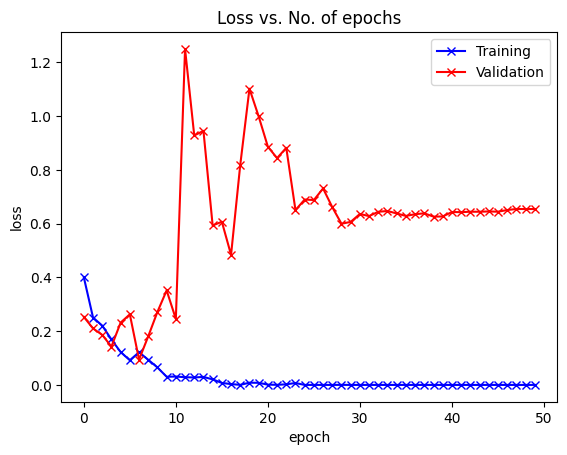

In [ ]:

plot_losses(history)

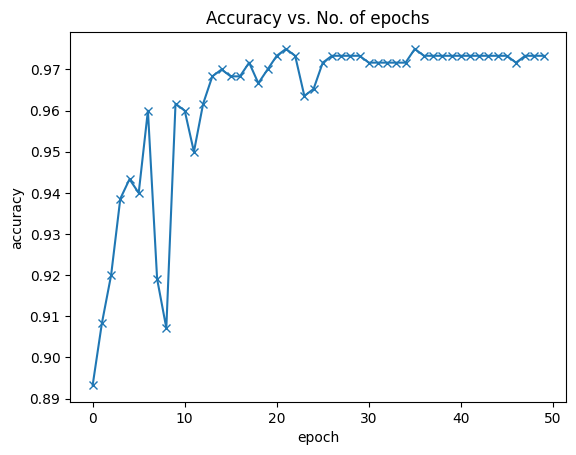

In [ ]:
plot_accuracies(history)

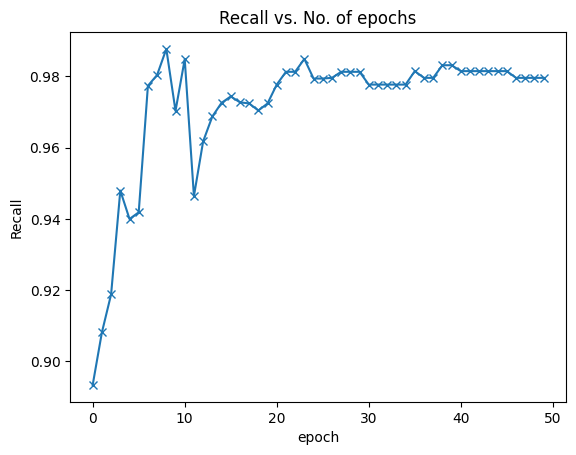

In [ ]:
plt.plot(history_recal, '-x')
plt.xlabel('epoch')
plt.ylabel('Recall')
plt.title('Recall vs. No. of epochs');

In [ ]:
arr=np.zeros((2,2))
for batch_idx, (data, targets) in enumerate(val_1d):
  batch=(data,targets)
  arr+=np.array(cm(model,batch))
arr

array([[ 66.,  18.],
       [ 24., 494.]])

In [ ]:
arr=np.zeros((2,2))
for batch_idx, (data, targets) in enumerate(val_1d):
  batch=(data,targets)
  arr+=np.array(cm(model,batch))
arr

array([[ 66.,  18.],
       [ 24., 494.]])

In [ ]:
v=[]
for batch_idx, (data, targets) in enumerate(val_1d):
  batch=(data,targets)
  v.append(np.array(f1(model,batch)))
np.array(v).mean()

0.9848761455412479

In [ ]:
v=[]
for batch_idx, (data, targets) in enumerate(val_1d):
  batch=(data,targets)
  v.append(np.array(ps(model,batch)))
np.array(v).mean()

0.9904645117994884

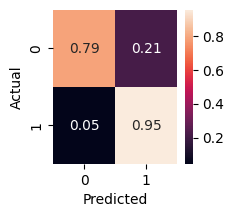

In [ ]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
arr=np.zeros((2,2))
for batch_idx, (data, targets) in enumerate(val_1d):
  batch=(data,targets)
  arr+=np.array(cm(model,batch))
# Normalise
cmn = arr.astype('float') / arr.sum(axis=1)[:, np.newaxis]
fig, ax = plt.subplots(figsize=(2,2))
sns.heatmap(cmn, annot=True, fmt='.2f')
plt.ylabel('Actual')
plt.xlabel('Predicted')
plt.show(block=False)